# 05 Summary: model development and final evaluation

This notebook collects the results of the project in one place, in the order
of the ML lifecycle. It does **not** train new models. It reads results that
were saved by earlier notebooks and by the scripts in `experiments/`, so it
runs in a few seconds.

| Step | Where the work was done |
|---|---|
| First models on PhiUSIIL | notebooks 01 and 02 |
| Selected model on PhreshPhish | notebook 03, saved as `models/phresh_text_model.joblib` |
| Homepage augmentation test | notebook 04 |
| Data audit and improvement experiments | `experiments/e00` to `e06` |
| Baseline against improved model | `experiments/e07_final_comparison.py` |
| Final test evaluation (run once) | `experiments/e08_final_test.py` |

Labels everywhere: **0 = phishing, 1 = legitimate**. "Phishing recall" is the
share of phishing URLs that the model flags.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "experiments"))
RESULTS = ROOT / "results" / "experiments"

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)


def load(name):
    return json.loads((RESULTS / f"{name}.json").read_text())

## 1. Data and evaluation setup

**Dataset.** PhreshPhish (Dalton et al., 2025, CC BY 4.0), pinned to one
dataset revision. The official train split has 498,255 URLs collected from
July 2024 to September 2025. The official test split (168,060 URLs) was
collected later, from September to December 2025, so testing on it checks
how the model handles newer URLs.

**How the data was divided.**

- **fit** (70%): training data.
- **val** (15%): choosing settings and the decision threshold.
- **holdout** (15%): comparing the final candidates once.
- **dev benchmark**: 10,000 URLs from the test split, already used in
  notebook 03, so it serves as a development check only.
- **final test**: 10,000 other URLs from the test split, untouched until
  the final model was chosen.

URLs from the **same website never appear in two of these parts**. If they
did, the model could memorise a website instead of learning general
patterns, and the test score would be too optimistic. In notebook 03, 31%
of validation rows shared a hostname with training rows.

**Popular homepages.** PhreshPhish has few legitimate homepages, so we also
test on homepages of popular websites from the Tranco top sites list
(list `Y83YG`, October 2026). These are typed as bare domains, for example
`example.com`, as a user would enter them. They are used for evaluation
only, never for training.

In [2]:
audit = load("e00_data_audit")
print("Train split rows:", audit["raw_train_rows"])
print("After removing duplicate URL texts:", audit["pool_rows_after_dedup"])
display(pd.DataFrame(audit["partitions"]).T)

Train split rows: 498255
After removing duplicate URL texts: 488728


,benign,phish
fit,183662,150238
holdout,46519,23448
val,46448,38413


## 2. Baseline model

The selected model from notebook 03 is a scikit-learn pipeline:

1. **Preprocessing** (`backend/features.py`): remove the scheme and a
   leading `www.`, keep hostname, path, query and fragment.
2. **Features**: character 3 to 5 grams weighted with TF-IDF (100,000
   features). This turns a URL into numbers, for example how often `log`,
   `ogi` and `gin` appear.
3. **Classifier**: `SGDClassifier(loss="log_loss", alpha=1e-4)`, which is
   logistic regression trained with stochastic gradient descent.

The table shows the deployed model and the same configuration retrained on
the larger fit partition. The deployed model was trained on a random sample
that includes websites from val, so its val numbers are optimistic. The dev
and popular homepage numbers are fair for both.

In [3]:
def overview(name):
    block = load(name)["far1"]
    return {
        "val PR-AUC": block["val_capped"]["pr_auc"],
        "val phishing recall": block["val_capped"]["recall"],
        "dev PR-AUC": block["dev"]["pr_auc"],
        "dev phishing recall": block["dev"]["recall"],
        "dev legitimate homepages flagged": block["dev"]["benign_homepage_far"]["rate"],
        "popular homepages flagged (Tranco top 10k)": block["tranco_homepages_val"]["top_10k"]["rate"],
    }


display(pd.DataFrame({
    "deployed model (24k rows)": overview("e01_production"),
    "same configuration, fit partition (334k rows)": overview("e01_baseline_full"),
}))

,deployed model (24k rows),"same configuration, fit partition (334k rows)"
val PR-AUC,0.9757,0.9750
val phishing recall,0.7785,0.7745
dev PR-AUC,0.9773,0.9767
dev phishing recall,0.7155,0.7255
dev legitimate homepages flagged,0.0330,0.0330
popular homepages flagged (Tranco top 10k),0.1880,0.1733


## 3. Metrics and threshold

- **Precision**: of the URLs we flag, how many are phishing.
- **Recall**: of the phishing URLs, how many we flag.
- **F1**: the harmonic mean of precision and recall.
- **PR-AUC**: the area under the precision-recall curve. It summarises
  performance over all thresholds.
- **False positive rate**: the share of legitimate URLs that we flag.

To compare models fairly, every model gets its own threshold, chosen on val
so that **1% of legitimate URLs are flagged**. This is the precision/recall
tradeoff from the course: a lower threshold catches more phishing but raises
more false alarms.

Why false alarms matter so much: phishing is rare in real browsing. If only
1% of checked links were phishing, a model with 80% recall and a 1.5% false
positive rate would give precision of only about 35%, so most warnings
would be false alarms. Users stop trusting a tool like that.

## 4. Error analysis: shortcuts in the data

### 4.1 PhiUSIIL: every legitimate URL has the same format

Notebook 02 reached 99.3% validation accuracy on PhiUSIIL, but predicted
`netflix.com` as phishing and `www.netflix.com` as legitimate. The reason is
visible in the raw URLs:

In [4]:
from urllib.parse import urlsplit

phiusiil = pd.read_csv(ROOT / "data" / "PhiUSIIL_Phishing_URL_Dataset.csv", usecols=["URL", "label"])
parsed = phiusiil["URL"].map(lambda url: urlsplit(url.strip()))
formats = pd.DataFrame({
    "label": phiusiil["label"].map({0: "phishing", 1: "legitimate"}),
    "starts with www.": parsed.map(lambda p: (p.hostname or "").startswith("www.")),
    "https": parsed.map(lambda p: p.scheme == "https"),
    "no path": parsed.map(lambda p: len(p.path) <= 1 and not p.query),
})
display(formats.groupby("label").mean().mul(100).round(1))

,starts with www.,https,no path
label,,,
legitimate,100.0,100.0,100.0
phishing,41.4,48.7,71.8


Every legitimate PhiUSIIL URL looks like `https://www.example.com`. A model
can separate the classes by format alone, without learning anything about
phishing. This is why we moved to PhreshPhish and remove `www.` during
preprocessing.

### 4.2 PhreshPhish: homepages and the trailing slash

PhreshPhish has a similar, weaker pattern:

In [5]:
from common import load_pool

pool = load_pool()
home = pool.loc[pool["homepage_like"]]
patterns = pd.DataFrame({
    "homepage-like URLs (% of label)": pool.groupby("label")["homepage_like"].mean().mul(100),
    "homepage-like URLs ending with / (%)": home.assign(slash=home["text"].str.endswith("/"))
        .groupby("label")["slash"].mean().mul(100),
}).round(1)
display(patterns)

,homepage-like URLs (% of label),homepage-like URLs ending with / (%)
label,,
benign,7.0,99.9
phish,45.1,86.7


- 45% of phishing URLs are bare homepages, but only 7% of legitimate URLs.
  The model therefore learns that a bare domain is suspicious.
- Almost every legitimate homepage in the data ends with `/`. A user who
  types `netflix.com` sends no slash, which makes the input look even more
  unusual to the model.

The consequence is the main weakness of the baseline: **about 17 to 19% of
popular homepages are flagged** (section 2). That includes sites such as
google.com and github.com. The problem is systematic, not limited to a
few examples.

## 5. Improvement attempts

All attempts used the same split, the same threshold rule and the same
evaluation sets.

### 5.1 Extra legitimate homepages and split features (notebook 04)

We generated legitimate homepage examples from legitimate training URLs and
tried separate TF-IDF features for hostname and path. Homepage false alarms
fell, but phishing homepage recall fell more, so no variant met the success
criteria fixed beforehand.

In [6]:
display(pd.read_csv(ROOT / "results" / "04_criteria.csv", index_col=0))

,C1 homepage FAR <= half of A0,C2 recall at matched FAR >= A0 - 0.01,C3 phishing homepage recall >= A0 - 0.03,C4 PR-AUC >= A0,C5 dev homepage FAR < A0,PASS
A1 augmented,True,False,False,False,True,False
A2 split,False,True,True,True,False,False
A3 split + augmented,True,False,False,False,True,False


### 5.2 Regularisation: a better score is not always a better product

We trained the baseline features with weaker regularisation (smaller
`alpha` for SGD, larger `C` for logistic regression). Left plot: the score
on PhreshPhish improves. Right plot: the share of popular homepages that
are flagged rises sharply with the original preprocessing (v1). A weakly
regularised model learns the "bare domain means phishing" pattern from 4.2
more strongly.

**Preprocessing v2** treats an empty path as `/`, so `netflix.com` and
`netflix.com/` become the same input. This is a feature engineering fix for
the trailing slash pattern, and it removes most of the damage.

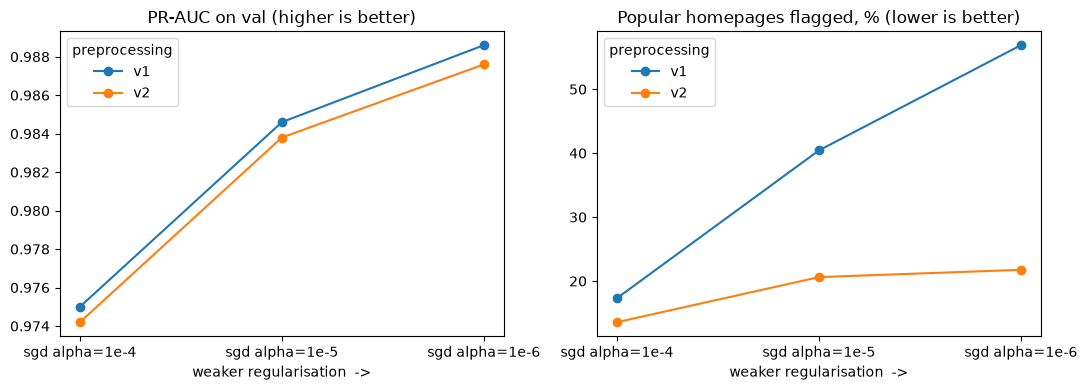

,val_capped PR-AUC,dev recall,Tranco top10k homepage FAR (val)
model,,,
e03 v1 | sgd alpha=1e-4,0.9750,0.7255,0.1733
e03 v1 | sgd alpha=1e-5,0.9846,0.8192,0.4043
e03 v1 | sgd alpha=1e-6,0.9886,0.8610,0.5688
e03 v1 | logreg C=0.1,0.9809,0.7862,0.2848
e03 v1 | logreg C=1,0.9872,0.8538,0.5165
e03 v1 | logreg C=10,0.9889,0.8608,0.5984
e03 v2 | sgd alpha=1e-4,0.9742,0.7144,0.1357
e03 v2 | sgd alpha=1e-5,0.9838,0.7957,0.2062
e03 v2 | sgd alpha=1e-6,0.9876,0.8188,0.2176


In [7]:
curve = pd.read_csv(RESULTS / "e03_summary.csv")
curve["preprocessing"] = curve["model"].str.extract(r"e03 (v\d)")
curve["setting"] = curve["model"].str.extract(r"\| (.*)$")

sgd = curve.loc[curve["setting"].str.startswith("sgd")]
order = ["sgd alpha=1e-4", "sgd alpha=1e-5", "sgd alpha=1e-6"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for version, group in sgd.groupby("preprocessing"):
    group = group.set_index("setting").loc[order]
    axes[0].plot(order, group["val_capped PR-AUC"], marker="o", label=version)
    axes[1].plot(order, group["Tranco top10k homepage FAR (val)"] * 100, marker="o", label=version)
axes[0].set_title("PR-AUC on val (higher is better)")
axes[1].set_title("Popular homepages flagged, % (lower is better)")
for ax in axes:
    ax.set_xlabel("weaker regularisation  ->")
    ax.legend(title="preprocessing")
plt.tight_layout()
plt.show()

display(curve.set_index("model")[["val_capped PR-AUC", "dev recall", "Tranco top10k homepage FAR (val)"]])

### 5.3 Structural features and tree models

Structural features describe the shape of a URL: hostname length, number of
dots, hyphens and digits, how random the first part of the hostname looks,
path length, and so on. Trees on these features alone rarely flag popular
homepages, but they miss about half of the phishing URLs. Combining them with
TF-IDF in one logistic model catches more phishing.

In [8]:
structural = pd.read_csv(RESULTS / "e04_summary.csv").set_index("model")
display(structural[["val_capped PR-AUC", "val_capped recall", "dev recall", "Tranco top10k homepage FAR (val)"]])
display(pd.read_csv(RESULTS / "e04_random_forest_importances.csv", index_col=0).head(8))

,val_capped PR-AUC,val_capped recall,dev recall,Tranco top10k homepage FAR (val)
model,,,,
e04 structural | decision tree depth 10,0.9134,0.4753,0.4449,0.0027
e04 structural | random forest,0.9436,0.6347,0.5008,0.0141
e04 structural | gradient boosting,0.9349,0.5768,0.5360,0.0060
e04 tfidf + structural | sgd alpha=1e-4,0.9674,0.7374,0.6878,0.0880
e04 tfidf + structural | sgd alpha=1e-6,0.9870,0.8763,0.8377,0.1773
e04 tfidf + structural | logreg C=1,0.9886,0.8729,0.8295,0.1981


,0
rest_slashes,0.2129
rest_len,0.1968
host_len,0.1551
host_labels,0.0781
host_hyphens,0.0614
no_path,0.0612
longest_label,0.0499
first_label_entropy,0.0463


We also tried an ensemble (stacking the text model and the tree model,
`experiments/e05_ensembles.py`). It was the best on several metrics, but it
needs two models and cross-validated predictions. We left it out to keep the
system simple to explain and deploy.

### 5.4 Learning curve

More training data helps the flexible model (TF-IDF + structural features,
weak regularisation) on PhreshPhish, but makes popular homepage false alarms
worse. The baseline stops improving after about 24,000 rows: it underfits
because of its strong regularisation.

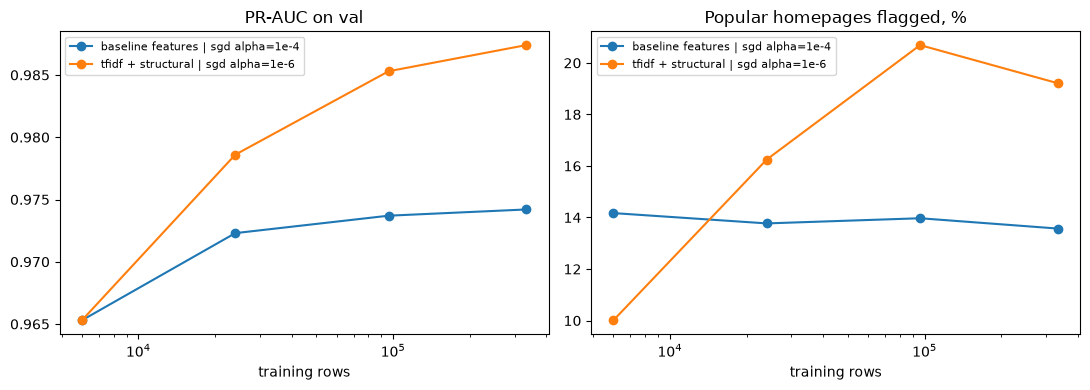

In [9]:
learning = pd.read_csv(RESULTS / "e06_learning_curve.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, group in learning.groupby("model"):
    axes[0].plot(group["train_rows"], group["val_capped PR-AUC"], marker="o", label=name)
    axes[1].plot(group["train_rows"], group["Tranco top10k homepage FAR (val)"] * 100, marker="o", label=name)
axes[0].set_title("PR-AUC on val")
axes[1].set_title("Popular homepages flagged, %")
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("training rows")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Final comparison: baseline against improved model

The best candidate from section 5 was **preprocessing v2 + TF-IDF +
structural features + LogisticRegression(C=1)**, chosen on val. It was
compared with the baseline once, on the holdout partition and the dev
benchmark, at the same 1% false positive rate.

The decision rule was written before running. Choose the improved model only
if phishing recall improves by at least 2 points, PR-AUC is not lower, and
homepage false alarms do not rise by more than 2 points.

In [10]:
comparison = pd.read_csv(RESULTS / "e07_final_comparison.csv", index_col=0)
display(comparison.round(4))
decision = load("e07_decision")
display(pd.Series(decision["criteria"], name="passed").to_frame())
print("Decision:", decision["decision"])

,baseline,improved,difference
threshold (from val),0.5483,0.6865,0.1382
holdout PR-AUC,0.9756,0.9888,0.0132
holdout phishing recall,0.7752,0.8749,0.0997
holdout precision,0.9843,0.9846,0.0003
holdout F1,0.8673,0.9265,0.0592
holdout false positive rate,0.0091,0.0099,0.0008
holdout benign homepage false alarms,0.0411,0.0755,0.0344
holdout phishing homepage recall,0.7873,0.8933,0.1060
dev PR-AUC,0.9767,0.9851,0.0084
dev phishing recall,0.7255,0.8295,0.1040


,passed
1 recall +0.02 on holdout and dev,True
2 PR-AUC not lower on holdout and dev,True
3 homepage false alarms rise at most 0.02,False


Decision: baseline


The improved model catches about **10 points more phishing** at the same
false positive rate, but flags about **3 points more legitimate homepages**,
which is the failure we most wanted to reduce. By the rule fixed in
advance, **we keep the baseline**.

## 7. Final test

The deployed baseline (`models/phresh_text_model.joblib`, threshold 0.5)
was evaluated **once** on the 10,000 reserved test URLs. Nothing was tuned
afterwards. Before the run, the evaluation code was checked on the dev
benchmark, where it reproduced the numbers from notebook 03 exactly.

,final test
accuracy,0.9057
precision,0.9770
phishing recall,0.8083
F1,0.8847
false positive rate,0.0154
PR-AUC,0.9769
legitimate homepages flagged,0.0655
phishing homepages caught,0.8469
phishing with brand name in hostname caught,0.8262


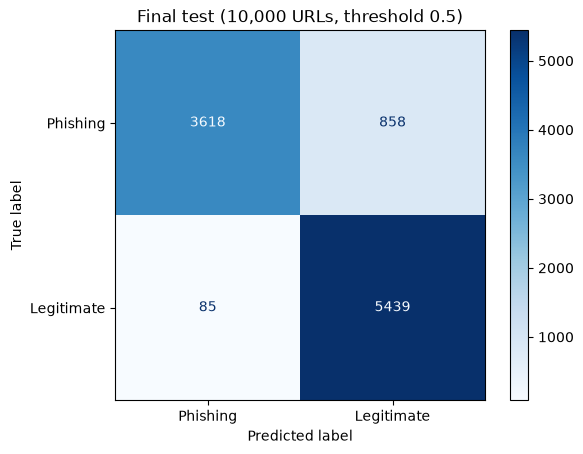

,websites seen in training,new websites
rows,2826.0000,7174.0000
recall,0.8828,0.8010
false positive rate,0.0058,0.0229


In [11]:
final = load("e08_final_test")
summary = {
    "accuracy": final["accuracy"],
    "precision": final["all"]["precision"],
    "phishing recall": final["all"]["recall"],
    "F1": final["all"]["f1"],
    "false positive rate": final["all"]["benign_far"],
    "PR-AUC": final["all"]["pr_auc"],
    "legitimate homepages flagged": final["all"]["benign_homepage_far"]["rate"],
    "phishing homepages caught": final["all"]["phish_homepage_recall"]["rate"],
    "phishing with brand name in hostname caught": final["brands"]["brand name in hostname"]["rate"],
}
display(pd.Series(summary, name="final test").to_frame())

from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np

matrix = np.array(final["confusion_matrix [[phish->phish, phish->benign], [benign->phish, benign->benign]]"])
ConfusionMatrixDisplay(matrix, display_labels=["Phishing", "Legitimate"]).plot(cmap="Blues", values_format="d")
plt.title("Final test (10,000 URLs, threshold 0.5)")
plt.show()

display(pd.DataFrame({
    "websites seen in training": {"rows": final["seen_site"]["n"], "recall": final["seen_site"]["recall"],
                                  "false positive rate": final["seen_site"]["benign_far"]},
    "new websites": {"rows": final["unseen_site"]["n"], "recall": final["unseen_site"]["recall"],
                     "false positive rate": final["unseen_site"]["benign_far"]},
}))

The final test agrees with the dev benchmark (accuracy 0.906 against 0.900,
recall 0.808 against 0.800), so the earlier results were not a lucky sample.

## 8. Limitations

- **Popular homepages.** About 17 to 19% of popular homepages are flagged.
  The training data contains few legitimate homepages, and no feature or
  setting we tried fixed this without losing phishing recall.
- **Missed phishing.** About 19% of phishing URLs in the final test pass
  unflagged. Many phishing pages are hosted on legitimate platforms (for
  example Google Sites, GitBook, Webflow), where the URL text looks normal.
- **Brand imitation.** Lookalike domains such as `netf1ix.com` are not
  reliably detected. The model has no list of real brand domains, and only
  about 6% of phishing URLs in the data contain the brand name in the
  hostname.
- **URL only.** The model never visits the page, so it cannot see the page
  content.
- **Scores are not probabilities.** The phishing score is uncalibrated and
  should not be shown as confidence.
- **Rare in reality.** At realistic phishing rates, many warnings will be
  false alarms (section 3).

## 9. What is deployed

- Model: `models/phresh_text_model.joblib` (unchanged).
- Preprocessing: `backend/features.py` (v1, unchanged).
- Decision: phishing if score >= 0.5 (`backend/main.py`).
- The website shows the prediction together with a note that it is a model
  signal, not a guarantee.